<a href="https://colab.research.google.com/github/samteccmrj/aqualimne/blob/main/analise_exploratoria.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# Bloco 1 — Importação e inspeção inicial dos dados

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Carregamento do arquivo CSV
arquivos = files.upload()
nome_arquivo = next(iter(arquivos))

# Leitura dos dados
df = pd.read_csv(
    nome_arquivo,
    sep=";",
    encoding="latin1",
    skiprows=1,
    decimal=",",
    na_values=["", "-", "--", "ND"]
)

# Conversão da coluna de data e hora
df["Data hora"] = pd.to_datetime(
    df["Data hora"],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

# Organização cronológica
df = df.sort_values("Data hora").reset_index(drop=True)

print("Dimensões do dataset:", df.shape)

print("\nColunas disponíveis:")
print(df.columns.tolist())

print("\nPrimeiros registros:")
display(df.head())

print("\nTipos de dados:")
print(df.dtypes)

print("\nPeríodo dos registros:")
print("Início:", df["Data hora"].min())
print("Fim:", df["Data hora"].max())

Saving ef08_cetesb_set2026.csv to ef08_cetesb_set2026.csv
Dimensões do dataset: (697, 7)

Colunas disponíveis:
['Data hora', 'pH', 'Oxigênio Dissolvido (mg/L)', 'Condutividade Elétrica (µS/cm)', 'Turbidez (NTU)', 'Temperatura (°C)', 'Precipitação (mm)']

Primeiros registros:


,Data hora,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C),Precipitação (mm)
0,2026-09-01 09:00:00,7.65,5.95,138.30,3.74,20.97,0.4
1,2026-09-01 10:00:00,7.63,5.86,138.42,3.60,20.95,1.0
2,2026-09-01 11:00:00,7.59,5.58,138.71,3.52,20.92,0.0
3,2026-09-01 12:00:00,7.55,5.15,139.05,3.32,20.88,0.0
4,2026-09-01 13:00:00,7.56,5.17,139.23,3.24,20.89,0.0



Tipos de dados:
Data hora                         datetime64[ns]
pH                                       float64
Oxigênio Dissolvido (mg/L)               float64
Condutividade Elétrica (µS/cm)           float64
Turbidez (NTU)                           float64
Temperatura (°C)                         float64
Precipitação (mm)                        float64
dtype: object

Período dos registros:
Início: 2026-09-01 09:00:00
Fim: 2026-09-30 09:00:00


In [ ]:

# Bloco 2 — Diagnóstico da qualidade dos dados

# 1. Valores ausentes
ausentes = pd.DataFrame({
    "Valores ausentes": df.isna().sum(),
    "Percentual (%)": (df.isna().mean() * 100).round(2)
})

print("1. VALORES AUSENTES")
display(ausentes)

# 2. Registros duplicados
print("\n2. DUPLICAÇÕES")
print("Linhas duplicadas:", df.duplicated().sum())
print(
    "Datas e horas duplicadas:",
    df["Data hora"].duplicated().sum()
)

# 3. Intervalos temporais
intervalos = df["Data hora"].diff().dropna()

print("\n3. INTERVALOS ENTRE MEDIÇÕES")
print(intervalos.value_counts().head(10))

# 4. Verificação de valores fisicamente inconsistentes
verificacoes = {
    "pH fora da faixa de 0 a 14":
        ((df["pH"] < 0) | (df["pH"] > 14)).sum(),

    "Oxigênio dissolvido negativo":
        (df["Oxigênio Dissolvido (mg/L)"] < 0).sum(),

    "Condutividade elétrica negativa":
        (df["Condutividade Elétrica (µS/cm)"] < 0).sum(),

    "Turbidez negativa":
        (df["Turbidez (NTU)"] < 0).sum(),

    "Precipitação negativa":
        (df["Precipitação (mm)"] < 0).sum()
}

print("\n4. VALORES FISICAMENTE INCONSISTENTES")
display(pd.DataFrame(
    verificacoes.items(),
    columns=["Verificação", "Ocorrências"]
))

1. VALORES AUSENTES


,Valores ausentes,Percentual (%)
Data hora,0,0.00
pH,72,10.33
Oxigênio Dissolvido (mg/L),72,10.33
Condutividade Elétrica (µS/cm),72,10.33
Turbidez (NTU),72,10.33
Temperatura (°C),72,10.33
Precipitação (mm),288,41.32



2. DUPLICAÇÕES
Linhas duplicadas: 0
Datas e horas duplicadas: 0

3. INTERVALOS ENTRE MEDIÇÕES
Data hora
0 days 01:00:00    696
Name: count, dtype: int64

4. VALORES FISICAMENTE INCONSISTENTES


,Verificação,Ocorrências
0,pH fora da faixa de 0 a 14,0
1,Oxigênio dissolvido negativo,0
2,Condutividade elétrica negativa,0
3,Turbidez negativa,0
4,Precipitação negativa,0


Horários com todos os cinco indicadores ausentes: 72
Horários com ausência parcial entre os indicadores: 0

Maiores períodos consecutivos de ausência:


,Inicio,Fim,Horas
grupo,,,
2,2026-09-18 09:00:00,2026-09-21 08:00:00,72


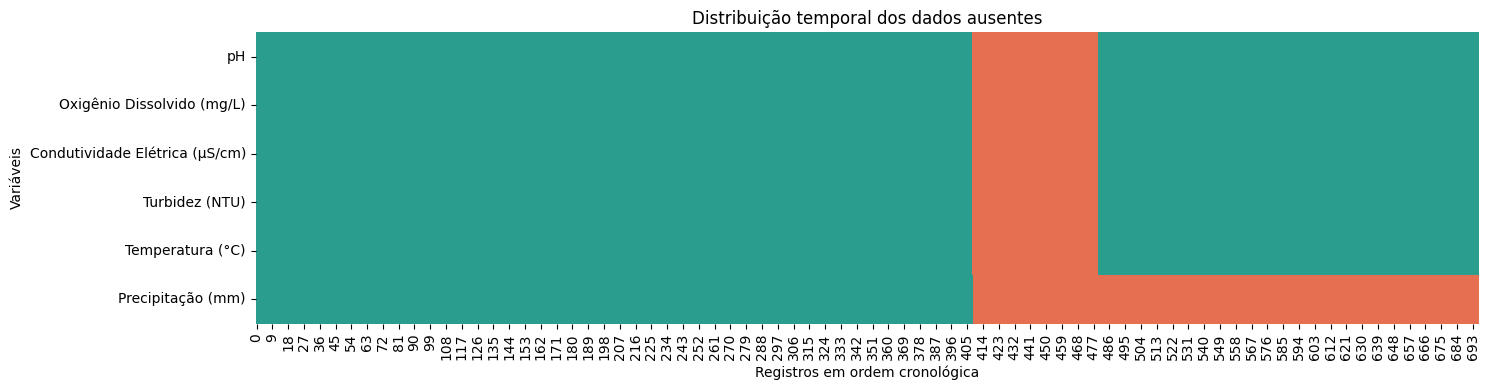

In [ ]:

# Bloco 3 — Padrões temporais dos dados ausentes

indicadores = [
    "pH",
    "Oxigênio Dissolvido (mg/L)",
    "Condutividade Elétrica (µS/cm)",
    "Turbidez (NTU)",
    "Temperatura (°C)"
]

# Verificar se os cinco indicadores estão ausentes juntos
ausencia_total = df[indicadores].isna().all(axis=1)
ausencia_parcial = (
    df[indicadores].isna().any(axis=1) & ~ausencia_total
)

print("Horários com todos os cinco indicadores ausentes:",
      ausencia_total.sum())

print("Horários com ausência parcial entre os indicadores:",
      ausencia_parcial.sum())

# Identificar sequências consecutivas de ausência
grupos = ausencia_total.ne(ausencia_total.shift()).cumsum()

periodos = (
    df.loc[ausencia_total, ["Data hora"]]
    .assign(grupo=grupos[ausencia_total].values)
    .groupby("grupo")
    .agg(
        Inicio=("Data hora", "min"),
        Fim=("Data hora", "max"),
        Horas=("Data hora", "size")
    )
    .sort_values("Horas", ascending=False)
)

print("\nMaiores períodos consecutivos de ausência:")
display(periodos.head(10))

# Mapa temporal das ausências
plt.figure(figsize=(15, 4))

colunas = indicadores + ["Precipitação (mm)"]

sns.heatmap(
    df[colunas].isna().T,
    cmap=["#2A9D8F", "#E76F51"],
    cbar=False,
    yticklabels=True
)

plt.title("Distribuição temporal dos dados ausentes")
plt.xlabel("Registros em ordem cronológica")
plt.ylabel("Variáveis")
plt.tight_layout()
plt.show()


In [ ]:

# Bloco 4 — Estatísticas descritivas

# Indicadores físico-químicos
indicadores = [
    "pH",
    "Oxigênio Dissolvido (mg/L)",
    "Condutividade Elétrica (µS/cm)",
    "Turbidez (NTU)",
    "Temperatura (°C)"
]

# Criar uma base específica para as análises
# sem modificar o dataset original
df_analise = df.dropna(subset=indicadores).copy()

print("REGISTROS")
print("Dataset original:", len(df))
print("Registros completos:", len(df_analise))
print("Registros excluídos desta análise:",
      len(df) - len(df_analise))

# Estatísticas descritivas
estatisticas = df_analise[indicadores].describe().T

estatisticas = estatisticas.rename(columns={
    "count": "Quantidade",
    "mean": "Média",
    "std": "Desvio-padrão",
    "min": "Mínimo",
    "25%": "1º Quartil",
    "50%": "Mediana",
    "75%": "3º Quartil",
    "max": "Máximo"
})

print("\nESTATÍSTICAS DESCRITIVAS")
display(estatisticas.round(2))

# Comparação entre média e mediana
comparacao = pd.DataFrame({
    "Média": df_analise[indicadores].mean(),
    "Mediana": df_analise[indicadores].median()
})

print("\nCOMPARAÇÃO ENTRE MÉDIA E MEDIANA")
display(comparacao.round(2))

REGISTROS
Dataset original: 697
Registros completos: 625
Registros excluídos desta análise: 72

ESTATÍSTICAS DESCRITIVAS


,Quantidade,Média,Desvio-padrão,Mínimo,1º Quartil,Mediana,3º Quartil,Máximo
pH,625.0,7.84,0.71,6.35,7.52,8.04,8.23,9.22
Oxigênio Dissolvido (mg/L),625.0,5.62,1.80,0.89,4.60,5.16,6.38,10.97
Condutividade Elétrica (µS/cm),625.0,141.01,2.15,135.05,139.98,140.78,142.02,150.07
Turbidez (NTU),625.0,3.18,0.82,1.56,2.45,3.24,3.85,5.87
Temperatura (°C),625.0,20.15,1.28,18.73,19.21,19.50,20.76,24.32



COMPARAÇÃO ENTRE MÉDIA E MEDIANA


,Média,Mediana
pH,7.84,8.04
Oxigênio Dissolvido (mg/L),5.62,5.16
Condutividade Elétrica (µS/cm),141.01,140.78
Turbidez (NTU),3.18,3.24
Temperatura (°C),20.15,19.50


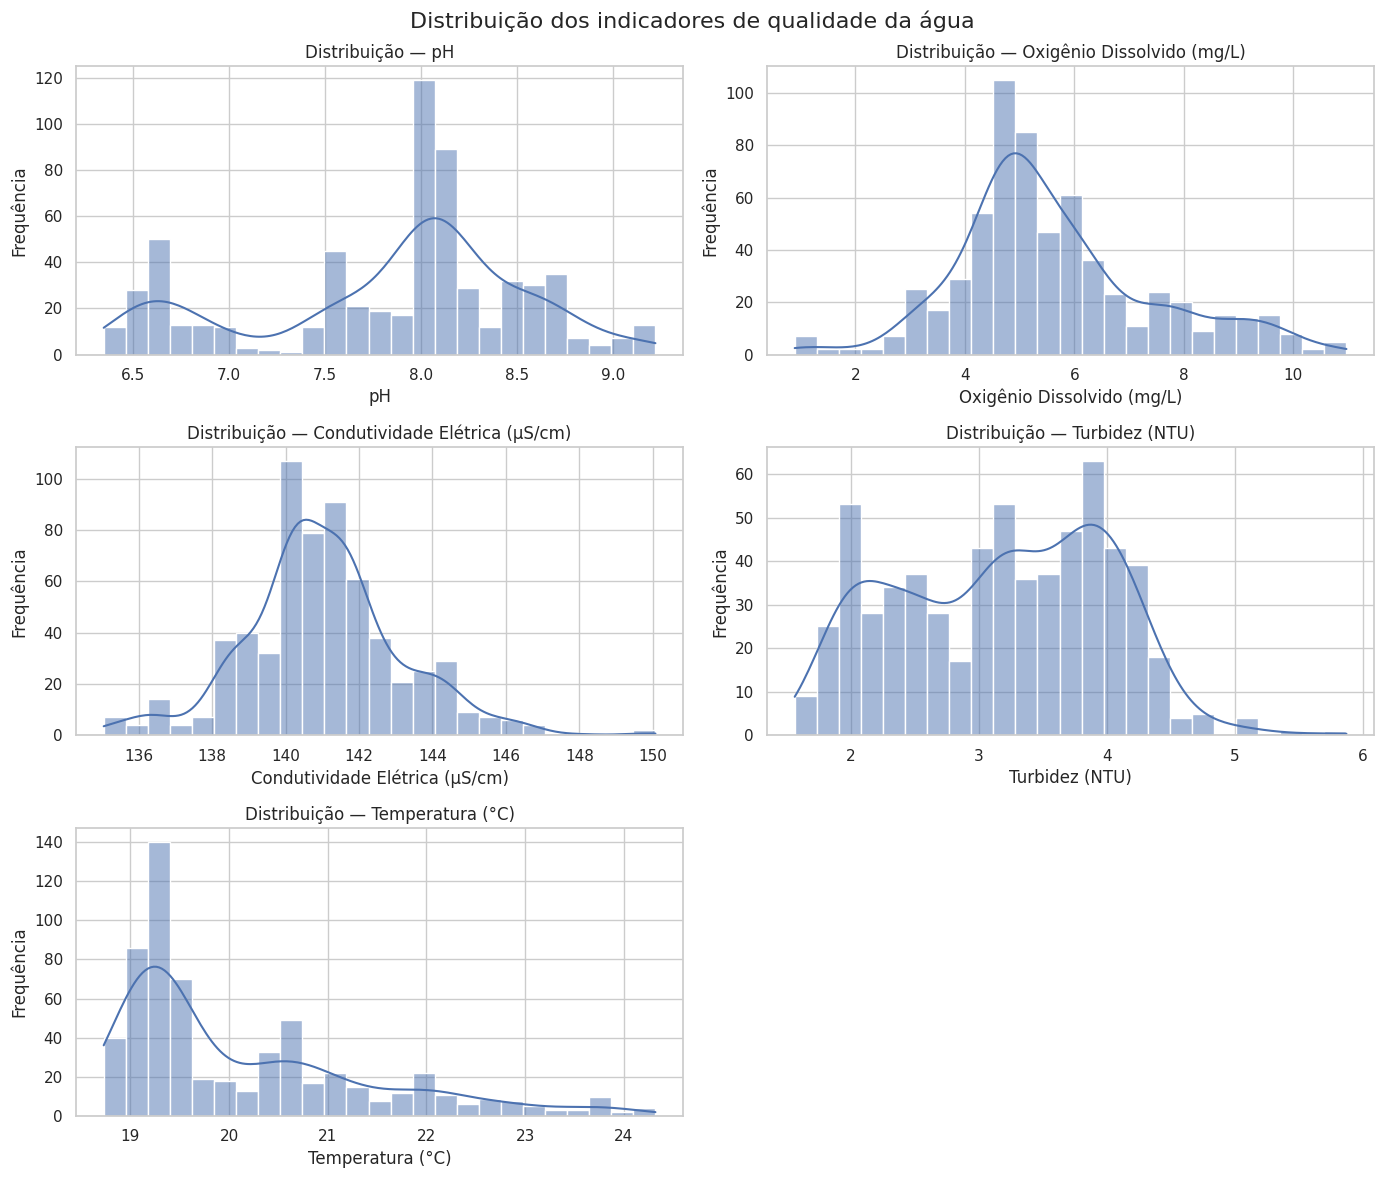

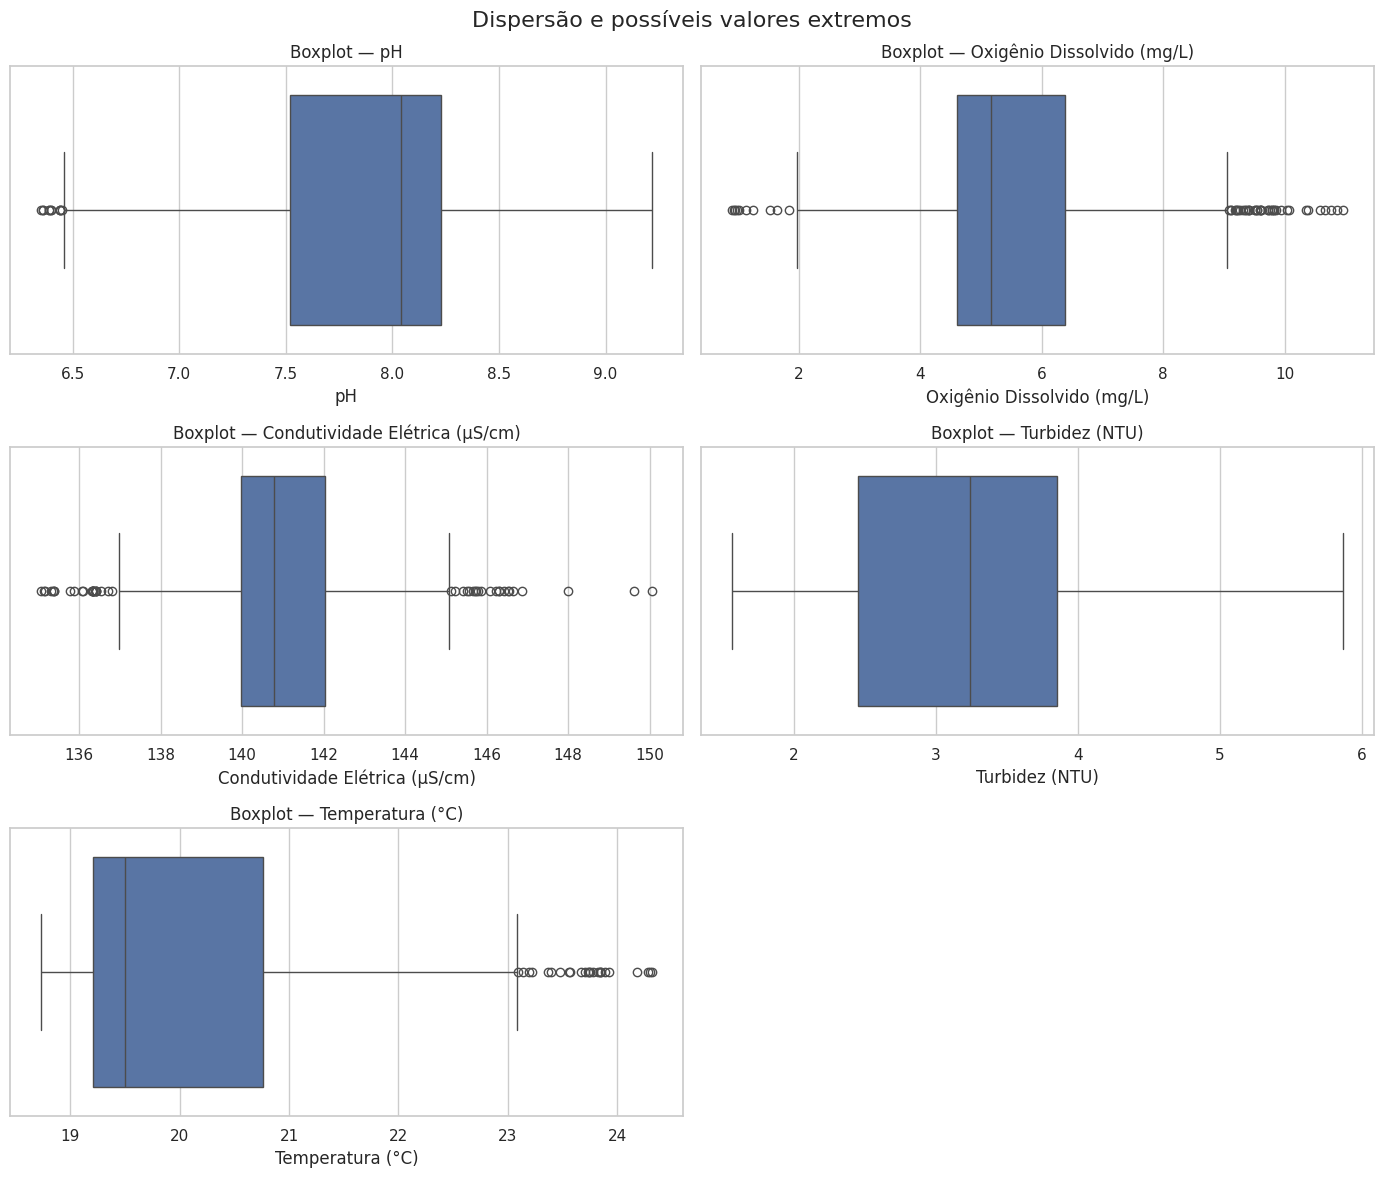

In [ ]:

# Bloco 5 — Distribuição dos indicadores

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

indicadores = [
    "pH",
    "Oxigênio Dissolvido (mg/L)",
    "Condutividade Elétrica (µS/cm)",
    "Turbidez (NTU)",
    "Temperatura (°C)"
]

# Histogramas
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, coluna in enumerate(indicadores):
    sns.histplot(
        data=df_analise,
        x=coluna,
        bins=25,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribuição — {coluna}")
    axes[i].set_ylabel("Frequência")
    axes[i].set_xlabel(coluna)

axes[-1].axis("off")

plt.suptitle(
    "Distribuição dos indicadores de qualidade da água",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Boxplots individuais
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, coluna in enumerate(indicadores):
    sns.boxplot(
        x=df_analise[coluna],
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot — {coluna}")
    axes[i].set_xlabel(coluna)

axes[-1].axis("off")

plt.suptitle(
    "Dispersão e possíveis valores extremos",
    fontsize=16
)

plt.tight_layout()
plt.show()


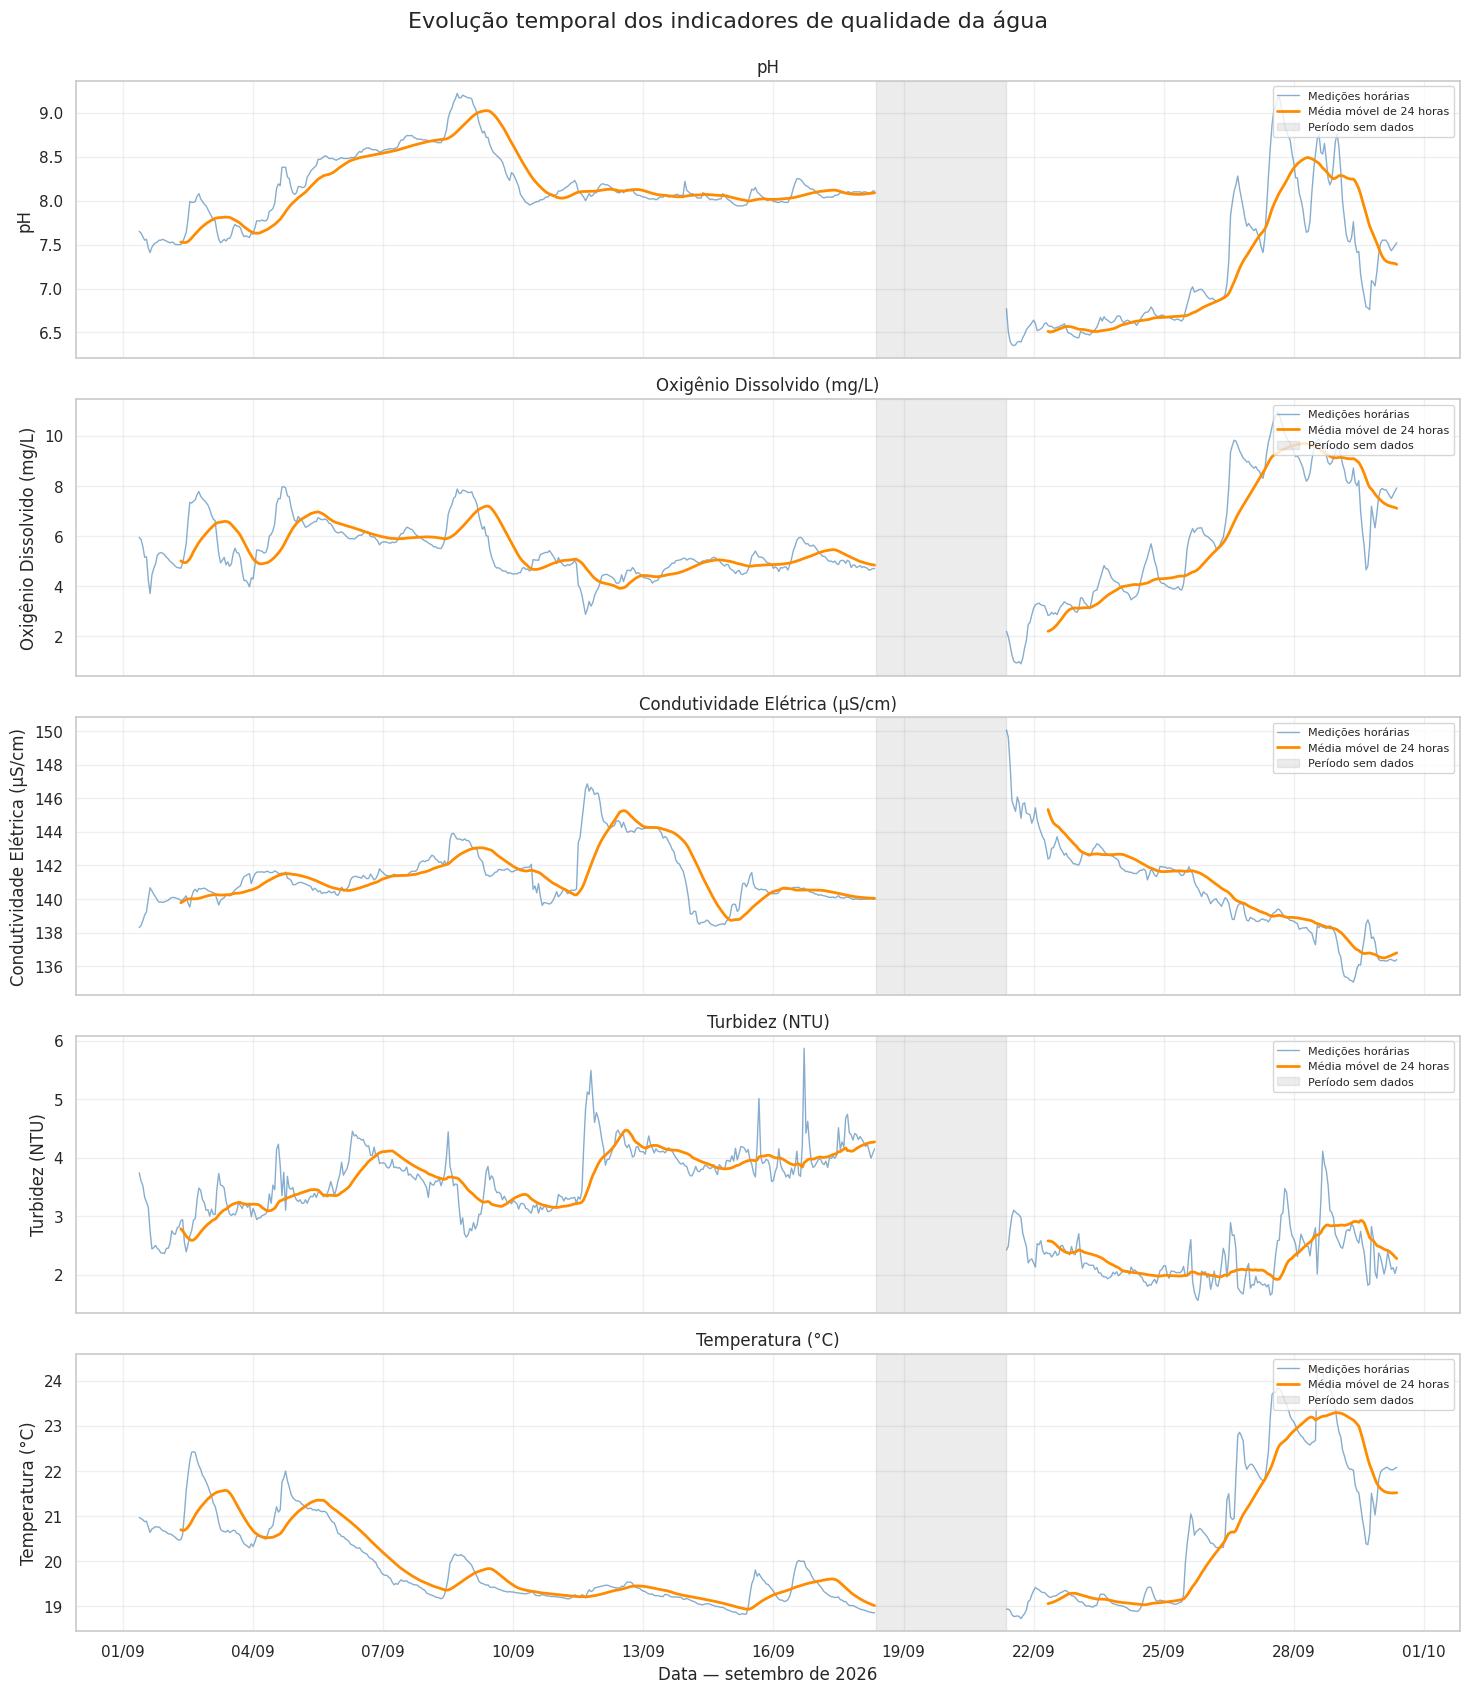

In [ ]:

# Bloco 6 — Evolução temporal dos indicadores

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

indicadores = [
    "pH",
    "Oxigênio Dissolvido (mg/L)",
    "Condutividade Elétrica (µS/cm)",
    "Turbidez (NTU)",
    "Temperatura (°C)"
]

# Usar a base original para preservar
# visualmente o período sem medições
df_temporal = df.sort_values("Data hora").copy()
df_temporal = df_temporal.set_index("Data hora")

fig, axes = plt.subplots(
    5, 1,
    figsize=(15, 17),
    sharex=True
)

for ax, coluna in zip(axes, indicadores):

    # Registros horários originais
    ax.plot(
        df_temporal.index,
        df_temporal[coluna],
        color="steelblue",
        linewidth=1,
        alpha=0.65,
        label="Medições horárias"
    )

    # Média móvel de 24 horas:
    # exige 24 observações válidas consecutivas
    media_movel = df_temporal[coluna].rolling(
        window=24,
        min_periods=24
    ).mean()

    ax.plot(
        df_temporal.index,
        media_movel,
        color="darkorange",
        linewidth=2,
        label="Média móvel de 24 horas"
    )

    # Período identificado sem registros
    ax.axvspan(
        pd.Timestamp("2026-09-18 09:00"),
        pd.Timestamp("2026-09-21 09:00"),
        color="gray",
        alpha=0.15,
        label="Período sem dados"
    )

    ax.set_title(coluna, fontsize=12)
    ax.set_ylabel(coluna)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)

axes[-1].xaxis.set_major_locator(
    mdates.DayLocator(interval=3)
)

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m")
)

axes[-1].set_xlabel("Data — setembro de 2026")

plt.suptitle(
    "Evolução temporal dos indicadores de qualidade da água",
    fontsize=16,
    y=0.995
)

plt.tight_layout()
plt.show()


MATRIZ DE CORRELAÇÃO — PEARSON


,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C)
pH,1.000,0.521,-0.129,0.613,0.235
Oxigênio Dissolvido (mg/L),0.521,1.000,-0.628,-0.157,0.854
Condutividade Elétrica (µS/cm),-0.129,-0.628,1.000,0.212,-0.565
Turbidez (NTU),0.613,-0.157,0.212,1.000,-0.304
Temperatura (°C),0.235,0.854,-0.565,-0.304,1.000



MATRIZ DE CORRELAÇÃO — SPEARMAN


,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C)
pH,1.000,0.488,-0.029,0.574,0.236
Oxigênio Dissolvido (mg/L),0.488,1.000,-0.588,-0.102,0.794
Condutividade Elétrica (µS/cm),-0.029,-0.588,1.000,0.149,-0.452
Turbidez (NTU),0.574,-0.102,0.149,1.000,-0.236
Temperatura (°C),0.236,0.794,-0.452,-0.236,1.000


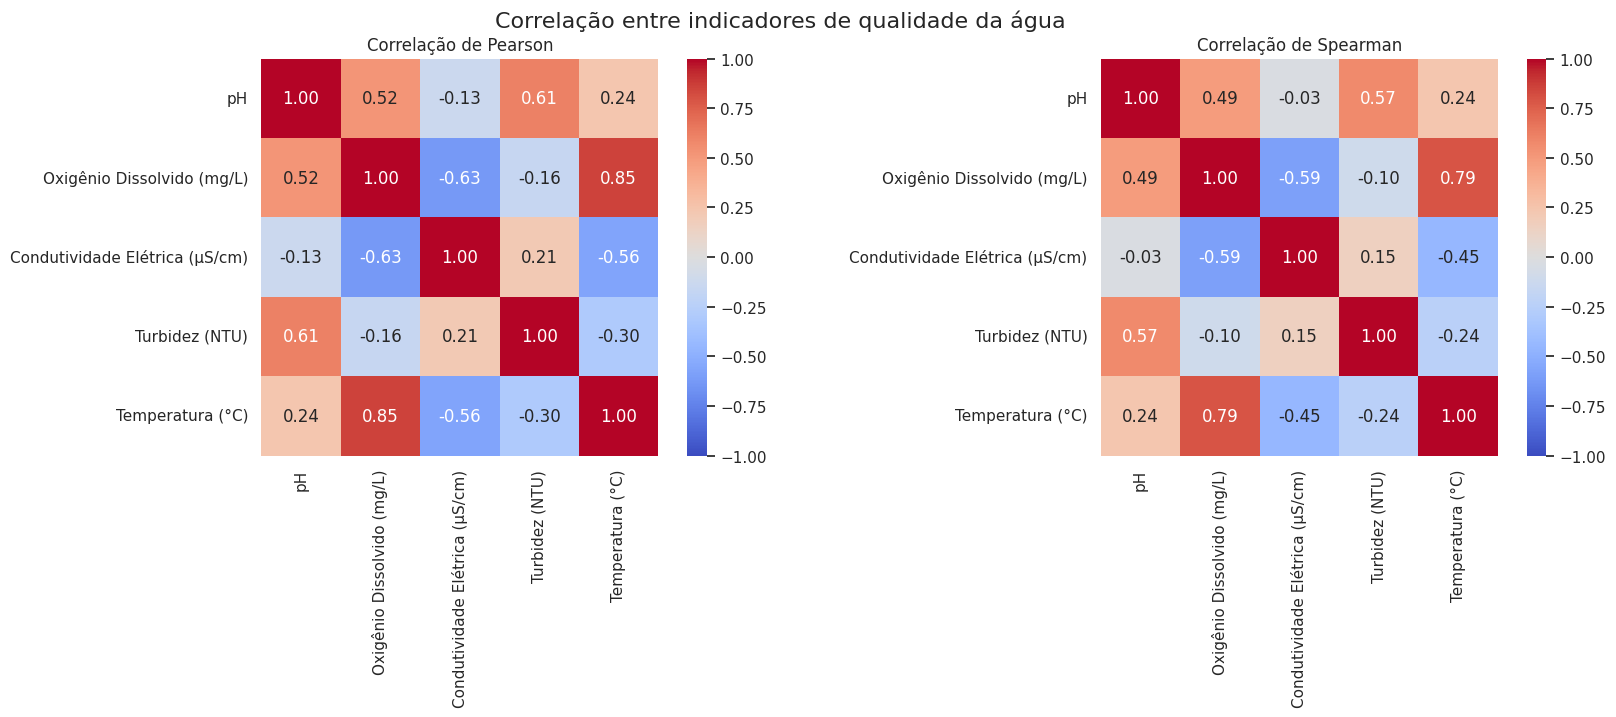


PARES ORDENADOS PELA CORRELAÇÃO DE PEARSON


,Indicador 1,Indicador 2,Pearson,Spearman
6,Oxigênio Dissolvido (mg/L),Temperatura (°C),0.854,0.794
4,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),-0.628,-0.588
2,pH,Turbidez (NTU),0.613,0.574
8,Condutividade Elétrica (µS/cm),Temperatura (°C),-0.565,-0.452
0,pH,Oxigênio Dissolvido (mg/L),0.521,0.488
9,Turbidez (NTU),Temperatura (°C),-0.304,-0.236
3,pH,Temperatura (°C),0.235,0.236
7,Condutividade Elétrica (µS/cm),Turbidez (NTU),0.212,0.149
5,Oxigênio Dissolvido (mg/L),Turbidez (NTU),-0.157,-0.102
1,pH,Condutividade Elétrica (µS/cm),-0.129,-0.029


In [ ]:

# Bloco 7 — Correlação entre indicadores

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

indicadores = [
    "pH",
    "Oxigênio Dissolvido (mg/L)",
    "Condutividade Elétrica (µS/cm)",
    "Turbidez (NTU)",
    "Temperatura (°C)"
]

# Utilizar apenas os registros completos
dados_correlacao = df_analise[indicadores].copy()

# Calcular as correlações
correlacao_pearson = dados_correlacao.corr(
    method="pearson"
)

correlacao_spearman = dados_correlacao.corr(
    method="spearman"
)

print("MATRIZ DE CORRELAÇÃO — PEARSON")
display(correlacao_pearson.round(3))

print("\nMATRIZ DE CORRELAÇÃO — SPEARMAN")
display(correlacao_spearman.round(3))

# Visualização das matrizes
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

sns.heatmap(
    correlacao_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)

axes[0].set_title("Correlação de Pearson")

sns.heatmap(
    correlacao_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)

axes[1].set_title("Correlação de Spearman")

plt.suptitle(
    "Correlação entre indicadores de qualidade da água",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Identificar os pares com maior correlação
# de Pearson, sem repetir combinações
pares = []

for i in range(len(indicadores)):
    for j in range(i + 1, len(indicadores)):
        pares.append({
            "Indicador 1": indicadores[i],
            "Indicador 2": indicadores[j],
            "Pearson": correlacao_pearson.iloc[i, j],
            "Spearman": correlacao_spearman.iloc[i, j]
        })

tabela_pares = pd.DataFrame(pares)

tabela_pares["Força absoluta"] = (
    tabela_pares["Pearson"].abs()
)

tabela_pares = tabela_pares.sort_values(
    "Força absoluta",
    ascending=False
)

print("\nPARES ORDENADOS PELA CORRELAÇÃO DE PEARSON")
display(
    tabela_pares.drop(
        columns="Força absoluta"
    ).round(3)
)


REGISTROS POR PERÍODO
Antes da interrupção: 408
Depois da interrupção: 217

COMPARAÇÃO DAS CORRELAÇÕES


,Par,Pearson antes,Pearson depois,Spearman antes,Spearman depois
0,Oxigênio Dissolvido (mg/L) × Temperatura (°C),0.630,0.945,0.589,0.905
1,Oxigênio Dissolvido (mg/L) × Condutividade Elé...,-0.164,-0.824,-0.100,-0.823
2,pH × Turbidez (NTU),0.165,0.358,0.220,0.093
3,Condutividade Elétrica (µS/cm) × Temperatura (°C),-0.146,-0.766,0.067,-0.787
4,pH × Oxigênio Dissolvido (mg/L),0.521,0.934,0.439,0.977


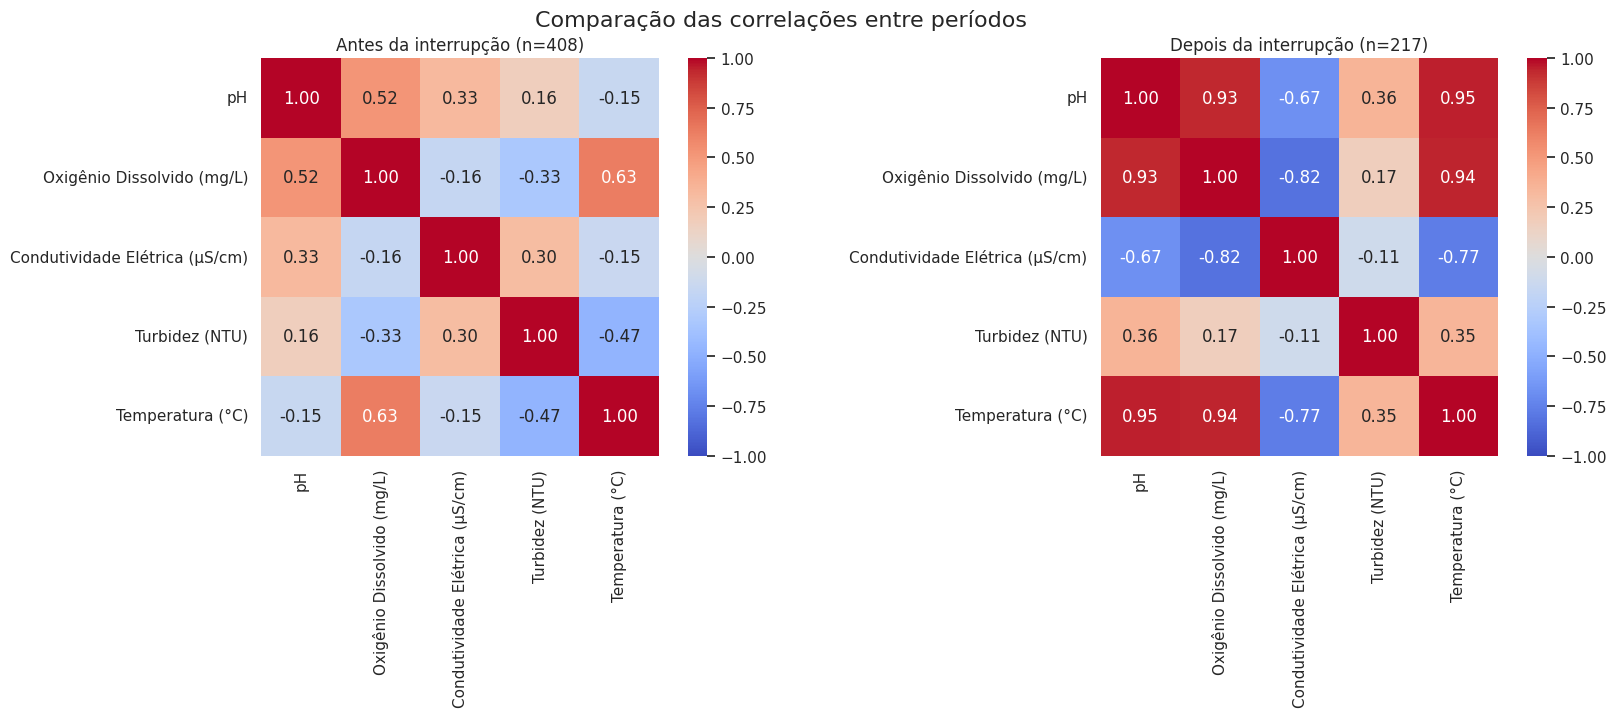

In [ ]:

# Bloco 8 — Correlações por período

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

indicadores = [
    "pH",
    "Oxigênio Dissolvido (mg/L)",
    "Condutividade Elétrica (µS/cm)",
    "Turbidez (NTU)",
    "Temperatura (°C)"
]

# Separação dos períodos
antes = df_analise[
    df_analise["Data hora"] <
    "2026-09-18 09:00:00"
].copy()

depois = df_analise[
    df_analise["Data hora"] >=
    "2026-09-21 09:00:00"
].copy()

print("REGISTROS POR PERÍODO")
print("Antes da interrupção:", len(antes))
print("Depois da interrupção:", len(depois))

# Matrizes de correlação
corr_antes = antes[indicadores].corr(method="pearson")
corr_depois = depois[indicadores].corr(method="pearson")

# Comparação de pares relevantes
pares = [
    ("Oxigênio Dissolvido (mg/L)", "Temperatura (°C)"),
    ("Oxigênio Dissolvido (mg/L)",
     "Condutividade Elétrica (µS/cm)"),
    ("pH", "Turbidez (NTU)"),
    ("Condutividade Elétrica (µS/cm)", "Temperatura (°C)"),
    ("pH", "Oxigênio Dissolvido (mg/L)")
]

resultados = []

for var1, var2 in pares:
    resultados.append({
        "Par": f"{var1} × {var2}",
        "Pearson antes": antes[var1].corr(antes[var2]),
        "Pearson depois": depois[var1].corr(depois[var2]),
        "Spearman antes": antes[var1].corr(
            antes[var2], method="spearman"
        ),
        "Spearman depois": depois[var1].corr(
            depois[var2], method="spearman"
        )
    })

comparacao = pd.DataFrame(resultados)

print("\nCOMPARAÇÃO DAS CORRELAÇÕES")
display(comparacao.round(3))

# Mapas de calor
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

sns.heatmap(
    corr_antes,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)

axes[0].set_title(
    f"Antes da interrupção (n={len(antes)})"
)

sns.heatmap(
    corr_depois,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)

axes[1].set_title(
    f"Depois da interrupção (n={len(depois)})"
)

plt.suptitle(
    "Comparação das correlações entre períodos",
    fontsize=16
)

plt.tight_layout()
plt.show()


REGISTROS DE VARIAÇÕES HORÁRIAS
Total: 623

CORRELAÇÃO DE PEARSON — VARIAÇÕES HORÁRIAS


,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C)
pH,1.000,0.745,-0.030,0.031,0.469
Oxigênio Dissolvido (mg/L),0.745,1.000,-0.213,0.055,0.479
Condutividade Elétrica (µS/cm),-0.030,-0.213,1.000,-0.095,0.131
Turbidez (NTU),0.031,0.055,-0.095,1.000,-0.102
Temperatura (°C),0.469,0.479,0.131,-0.102,1.000



CORRELAÇÃO DE SPEARMAN — VARIAÇÕES HORÁRIAS


,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C)
pH,1.000,0.780,-0.021,-0.001,0.532
Oxigênio Dissolvido (mg/L),0.780,1.000,-0.118,-0.019,0.556
Condutividade Elétrica (µS/cm),-0.021,-0.118,1.000,-0.058,0.109
Turbidez (NTU),-0.001,-0.019,-0.058,1.000,-0.000
Temperatura (°C),0.532,0.556,0.109,-0.000,1.000


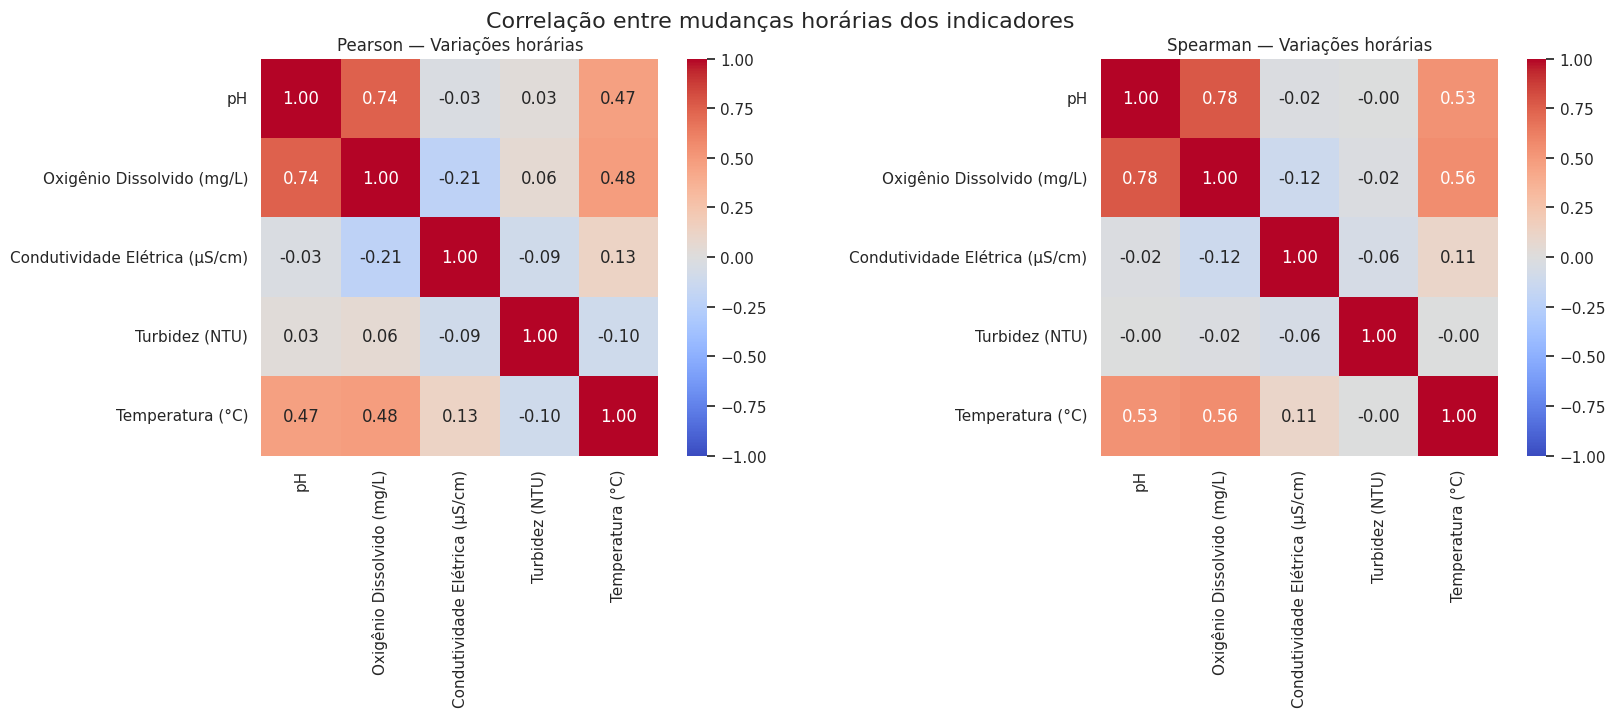


COMPARAÇÃO: VALORES ABSOLUTOS × VARIAÇÕES


,Par,Pearson nos valores,Pearson nas variações
0,Oxigênio Dissolvido (mg/L) × Temperatura (°C),0.854,0.479
1,pH × Oxigênio Dissolvido (mg/L),0.521,0.745
2,Oxigênio Dissolvido (mg/L) × Condutividade Elé...,-0.628,-0.213


In [ ]:

# Bloco 9 — Correlação das variações horárias

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

indicadores = [
    "pH",
    "Oxigênio Dissolvido (mg/L)",
    "Condutividade Elétrica (µS/cm)",
    "Turbidez (NTU)",
    "Temperatura (°C)"
]

# Organizar os dados cronologicamente
dados = df_analise.sort_values("Data hora").copy()

# Calcular o intervalo entre registros consecutivos
dados["Intervalo"] = dados["Data hora"].diff()

# Calcular variações entre registros consecutivos
variacoes = dados[indicadores].diff()

# Manter somente diferenças entre horas consecutivas
intervalos_validos = (
    dados["Intervalo"] == pd.Timedelta(hours=1)
)

variacoes = variacoes.loc[intervalos_validos].copy()

print("REGISTROS DE VARIAÇÕES HORÁRIAS")
print("Total:", len(variacoes))

# Correlações das variações horárias
corr_pearson = variacoes.corr(method="pearson")
corr_spearman = variacoes.corr(method="spearman")

print("\nCORRELAÇÃO DE PEARSON — VARIAÇÕES HORÁRIAS")
display(corr_pearson.round(3))

print("\nCORRELAÇÃO DE SPEARMAN — VARIAÇÕES HORÁRIAS")
display(corr_spearman.round(3))

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)

axes[0].set_title("Pearson — Variações horárias")

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)

axes[1].set_title("Spearman — Variações horárias")

plt.suptitle(
    "Correlação entre mudanças horárias dos indicadores",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Comparar associações em níveis e variações
pares = [
    ("Oxigênio Dissolvido (mg/L)", "Temperatura (°C)"),
    ("pH", "Oxigênio Dissolvido (mg/L)"),
    ("Oxigênio Dissolvido (mg/L)",
     "Condutividade Elétrica (µS/cm)")
]

comparacao = []

for var1, var2 in pares:
    comparacao.append({
        "Par": f"{var1} × {var2}",
        "Pearson nos valores": df_analise[var1].corr(
            df_analise[var2]
        ),
        "Pearson nas variações": corr_pearson.loc[
            var1, var2
        ]
    })

print("\nCOMPARAÇÃO: VALORES ABSOLUTOS × VARIAÇÕES")
display(pd.DataFrame(comparacao).round(3))


REGISTROS DE VARIAÇÕES HORÁRIAS
Total: 623

CORRELAÇÃO DE PEARSON — VARIAÇÕES HORÁRIAS


,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C)
pH,1.000,0.745,-0.030,0.031,0.469
Oxigênio Dissolvido (mg/L),0.745,1.000,-0.213,0.055,0.479
Condutividade Elétrica (µS/cm),-0.030,-0.213,1.000,-0.095,0.131
Turbidez (NTU),0.031,0.055,-0.095,1.000,-0.102
Temperatura (°C),0.469,0.479,0.131,-0.102,1.000



CORRELAÇÃO DE SPEARMAN — VARIAÇÕES HORÁRIAS


,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C)
pH,1.000,0.780,-0.021,-0.001,0.532
Oxigênio Dissolvido (mg/L),0.780,1.000,-0.118,-0.019,0.556
Condutividade Elétrica (µS/cm),-0.021,-0.118,1.000,-0.058,0.109
Turbidez (NTU),-0.001,-0.019,-0.058,1.000,-0.000
Temperatura (°C),0.532,0.556,0.109,-0.000,1.000


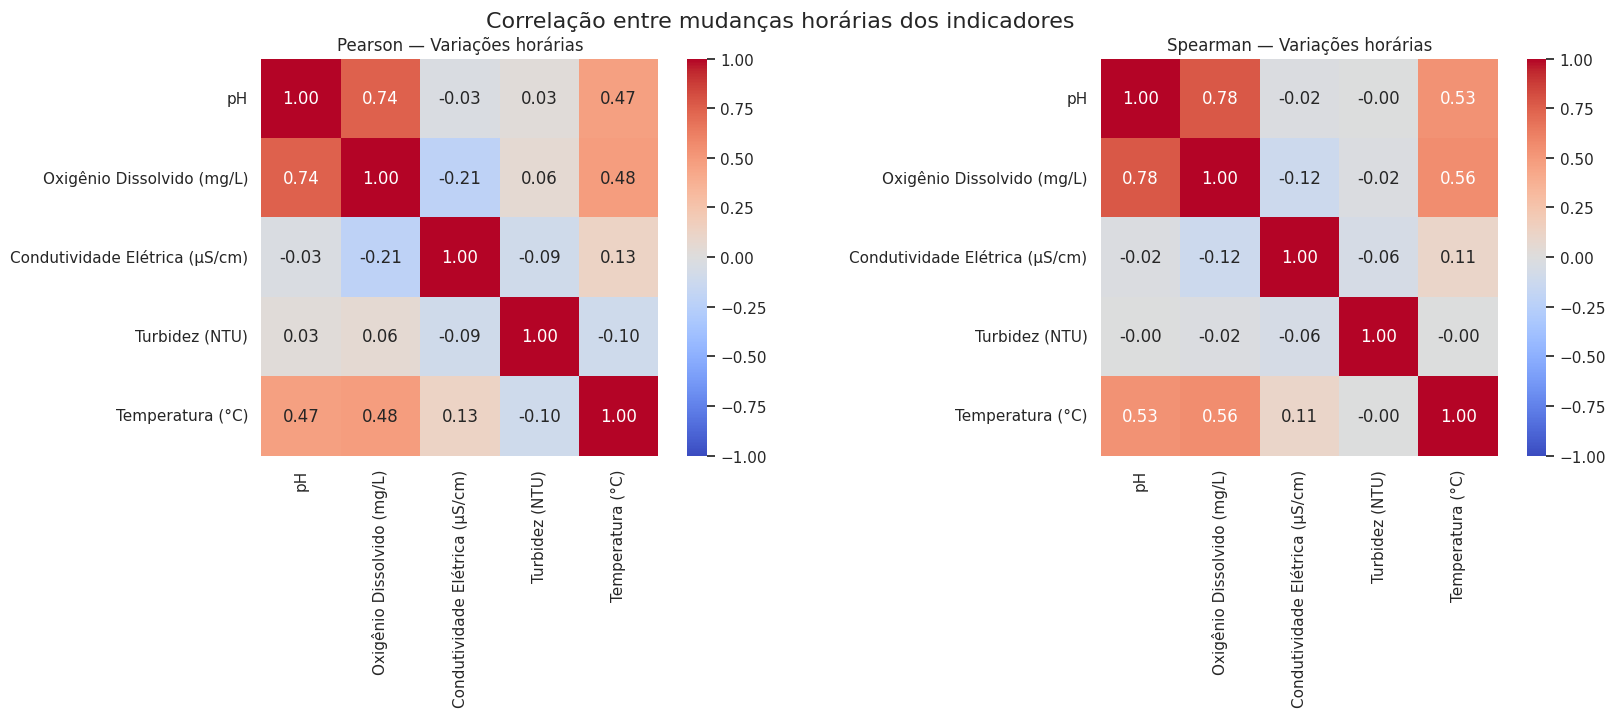


COMPARAÇÃO: VALORES ABSOLUTOS × VARIAÇÕES


,Par,Pearson nos valores,Pearson nas variações
0,Oxigênio Dissolvido (mg/L) × Temperatura (°C),0.854,0.479
1,pH × Oxigênio Dissolvido (mg/L),0.521,0.745
2,Oxigênio Dissolvido (mg/L) × Condutividade Elé...,-0.628,-0.213


In [ ]:

# Bloco 9 — Correlação das variações horárias

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

indicadores = [
    "pH",
    "Oxigênio Dissolvido (mg/L)",
    "Condutividade Elétrica (µS/cm)",
    "Turbidez (NTU)",
    "Temperatura (°C)"
]

# Organizar os dados cronologicamente
dados = df_analise.sort_values("Data hora").copy()

# Calcular o intervalo entre registros consecutivos
dados["Intervalo"] = dados["Data hora"].diff()

# Calcular variações entre registros consecutivos
variacoes = dados[indicadores].diff()

# Manter somente diferenças entre horas consecutivas
intervalos_validos = (
    dados["Intervalo"] == pd.Timedelta(hours=1)
)

variacoes = variacoes.loc[intervalos_validos].copy()

print("REGISTROS DE VARIAÇÕES HORÁRIAS")
print("Total:", len(variacoes))

# Correlações das variações horárias
corr_pearson = variacoes.corr(method="pearson")
corr_spearman = variacoes.corr(method="spearman")

print("\nCORRELAÇÃO DE PEARSON — VARIAÇÕES HORÁRIAS")
display(corr_pearson.round(3))

print("\nCORRELAÇÃO DE SPEARMAN — VARIAÇÕES HORÁRIAS")
display(corr_spearman.round(3))

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

sns.heatmap(
    corr_pearson,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[0]
)

axes[0].set_title("Pearson — Variações horárias")

sns.heatmap(
    corr_spearman,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    ax=axes[1]
)

axes[1].set_title("Spearman — Variações horárias")

plt.suptitle(
    "Correlação entre mudanças horárias dos indicadores",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Comparar associações em níveis e variações
pares = [
    ("Oxigênio Dissolvido (mg/L)", "Temperatura (°C)"),
    ("pH", "Oxigênio Dissolvido (mg/L)"),
    ("Oxigênio Dissolvido (mg/L)",
     "Condutividade Elétrica (µS/cm)")
]

comparacao = []

for var1, var2 in pares:
    comparacao.append({
        "Par": f"{var1} × {var2}",
        "Pearson nos valores": df_analise[var1].corr(
            df_analise[var2]
        ),
        "Pearson nas variações": corr_pearson.loc[
            var1, var2
        ]
    })

print("\nCOMPARAÇÃO: VALORES ABSOLUTOS × VARIAÇÕES")
display(pd.DataFrame(comparacao).round(3))


In [ ]:

# Bloco 10 — Preparação dos dados para Machine Learning

import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler

indicadores = [
    "pH",
    "Oxigênio Dissolvido (mg/L)",
    "Condutividade Elétrica (µS/cm)",
    "Turbidez (NTU)",
    "Temperatura (°C)"
]

# Preservar apenas registros completos
dados_ml = (
    df_analise[["Data hora"] + indicadores]
    .sort_values("Data hora")
    .copy()
    .reset_index(drop=True)
)

# Matriz de entrada
X = dados_ml[indicadores].copy()

print("DIMENSÕES DA MATRIZ ORIGINAL")
print(X.shape)

print("\nVALORES AUSENTES")
print(X.isna().sum())

# Padronização das variáveis
scaler = StandardScaler()

X_padronizado = scaler.fit_transform(X)

# Converter para DataFrame
X_padronizado = pd.DataFrame(
    X_padronizado,
    columns=indicadores,
    index=X.index
)

print("\nESTATÍSTICAS APÓS PADRONIZAÇÃO")
display(
    pd.DataFrame({
        "Média": X_padronizado.mean(),
        "Desvio-padrão": X_padronizado.std(ddof=0),
        "Mínimo": X_padronizado.min(),
        "Máximo": X_padronizado.max()
    }).round(3)
)

print("\nPRIMEIROS REGISTROS PADRONIZADOS")
display(X_padronizado.head())

print("\nVERIFICAÇÃO FINAL")
print("Registros utilizados:", len(X_padronizado))
print("Variáveis utilizadas:", X_padronizado.shape[1])
print(
    "Existem valores ausentes?",
    X_padronizado.isna().any().any()
)


DIMENSÕES DA MATRIZ ORIGINAL
(625, 5)

VALORES AUSENTES
pH                                0
Oxigênio Dissolvido (mg/L)        0
Condutividade Elétrica (µS/cm)    0
Turbidez (NTU)                    0
Temperatura (°C)                  0
dtype: int64

ESTATÍSTICAS APÓS PADRONIZAÇÃO


,Média,Desvio-padrão,Mínimo,Máximo
pH,-0.0,1.0,-2.105,1.960
Oxigênio Dissolvido (mg/L),-0.0,1.0,-2.628,2.978
Condutividade Elétrica (µS/cm),0.0,1.0,-2.779,4.222
Turbidez (NTU),0.0,1.0,-1.976,3.283
Temperatura (°C),-0.0,1.0,-1.114,3.262



PRIMEIROS REGISTROS PADRONIZADOS


,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C)
0,-0.263740,0.186083,-1.263788,0.683961,0.639289
1,-0.292072,0.136027,-1.207855,0.513118,0.623632
2,-0.348737,-0.019702,-1.072683,0.415492,0.600147
3,-0.405401,-0.258857,-0.914206,0.171430,0.568833
4,-0.391235,-0.247734,-0.830307,0.073805,0.576661



VERIFICAÇÃO FINAL
Registros utilizados: 625
Variáveis utilizadas: 5
Existem valores ausentes? False


RESULTADOS DO ISOLATION FOREST
Total de registros: 625

CLASSIFICAÇÃO


,Situação,Quantidade
0,Regular,593
1,Anomalia potencial,32



Percentual sinalizado: 5.12%

10 REGISTROS MAIS INCOMUNS


,Data hora,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C),Pontuacao_anomalia
558,2026-09-27 15:00:00,9.17,10.97,139.39,2.58,23.84,0.636
559,2026-09-27 16:00:00,9.18,10.87,139.38,2.59,23.82,0.634
556,2026-09-27 13:00:00,9.03,10.67,139.18,2.04,23.75,0.629
410,2026-09-21 11:00:00,6.40,1.64,148.01,2.78,18.91,0.629
557,2026-09-27 14:00:00,9.07,10.77,139.25,2.35,23.74,0.626
408,2026-09-21 09:00:00,6.77,2.19,150.07,2.42,18.94,0.626
555,2026-09-27 12:00:00,8.87,10.38,139.07,1.68,23.70,0.623
583,2026-09-28 16:00:00,8.53,9.54,138.32,4.11,24.18,0.622
414,2026-09-21 15:00:00,6.39,0.93,146.08,3.04,18.79,0.621
409,2026-09-21 10:00:00,6.51,1.97,149.63,2.49,18.94,0.621


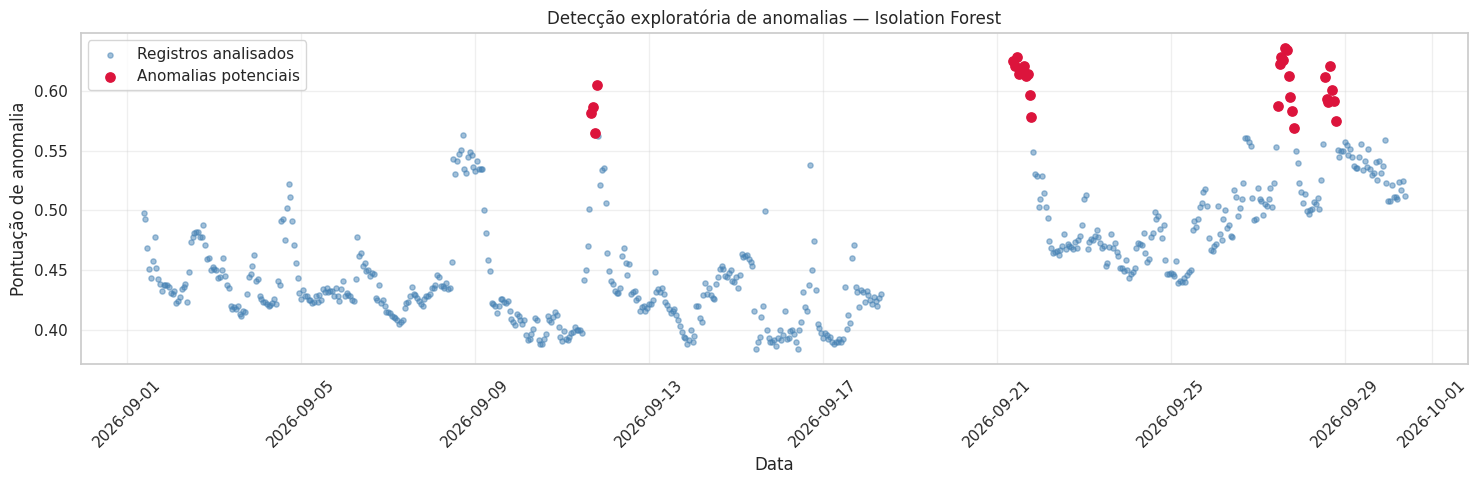

In [ ]:

# Bloco 11 — Detecção de anomalias com Isolation Forest

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

# Configuração experimental do modelo
modelo = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

# Treinamento e classificação exploratória
predicoes = modelo.fit_predict(X_padronizado)

# Pontuação de anomalia:
# valores maiores indicam observações mais incomuns
pontuacoes = -modelo.score_samples(X_padronizado)

# Preservar os dados originais
resultados_ml = dados_ml.copy()

resultados_ml["Classificacao"] = predicoes
resultados_ml["Pontuacao_anomalia"] = pontuacoes

resultados_ml["Situacao"] = resultados_ml[
    "Classificacao"
].map({
    1: "Regular",
    -1: "Anomalia potencial"
})

# Resumo
print("RESULTADOS DO ISOLATION FOREST")
print("Total de registros:", len(resultados_ml))

print("\nCLASSIFICAÇÃO")
display(
    resultados_ml["Situacao"]
    .value_counts()
    .rename_axis("Situação")
    .reset_index(name="Quantidade")
)

percentual = (
    (resultados_ml["Classificacao"] == -1).mean() * 100
)

print(f"\nPercentual sinalizado: {percentual:.2f}%")

# Registros com maiores pontuações
print("\n10 REGISTROS MAIS INCOMUNS")

top_anomalias = (
    resultados_ml[
        resultados_ml["Classificacao"] == -1
    ]
    .sort_values(
        "Pontuacao_anomalia",
        ascending=False
    )
    .head(10)
)

display(
    top_anomalias[
        ["Data hora"] +
        indicadores +
        ["Pontuacao_anomalia"]
    ].round(3)
)

# Visualização temporal dos alertas
fig, ax = plt.subplots(figsize=(15, 5))

ax.scatter(
    resultados_ml["Data hora"],
    resultados_ml["Pontuacao_anomalia"],
    s=14,
    alpha=0.5,
    color="steelblue",
    label="Registros analisados"
)

anomalias = resultados_ml[
    resultados_ml["Classificacao"] == -1
]

ax.scatter(
    anomalias["Data hora"],
    anomalias["Pontuacao_anomalia"],
    s=45,
    color="crimson",
    label="Anomalias potenciais",
    zorder=3
)

ax.set_title(
    "Detecção exploratória de anomalias — Isolation Forest"
)

ax.set_xlabel("Data")
ax.set_ylabel("Pontuação de anomalia")

ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


COMPARAÇÃO DOS MÉTODOS


,Classificação,Quantidade
0,Somente Isolation Forest,25
1,Somente Z-score,1
2,Ambos os métodos,7
3,Nenhum dos métodos,592



TOTAL DE ALERTAS POR MÉTODO
Isolation Forest: 32
Z-score: 8

TABELA CRUZADA


Z-score,False,True
Isolation Forest,,
False,592,1
True,25,7



10 PRINCIPAIS ALERTAS EXCLUSIVOS DO ISOLATION FOREST


,Data hora,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C),Pontuacao_anomalia,Z_maximo
558,2026-09-27 15:00:00,9.17,10.97,139.39,2.58,23.84,0.636,2.978
559,2026-09-27 16:00:00,9.18,10.87,139.38,2.59,23.82,0.634,2.922
556,2026-09-27 13:00:00,9.03,10.67,139.18,2.04,23.75,0.629,2.816
557,2026-09-27 14:00:00,9.07,10.77,139.25,2.35,23.74,0.626,2.867
555,2026-09-27 12:00:00,8.87,10.38,139.07,1.68,23.70,0.623,2.776
414,2026-09-21 15:00:00,6.39,0.93,146.08,3.04,18.79,0.621,2.606
412,2026-09-21 13:00:00,6.35,1.01,145.53,3.10,18.78,0.618,2.561
413,2026-09-21 14:00:00,6.36,0.94,145.22,3.07,18.78,0.617,2.600
411,2026-09-21 12:00:00,6.36,1.25,145.87,3.00,18.82,0.615,2.428
416,2026-09-21 17:00:00,6.39,0.89,144.81,2.97,18.73,0.614,2.628


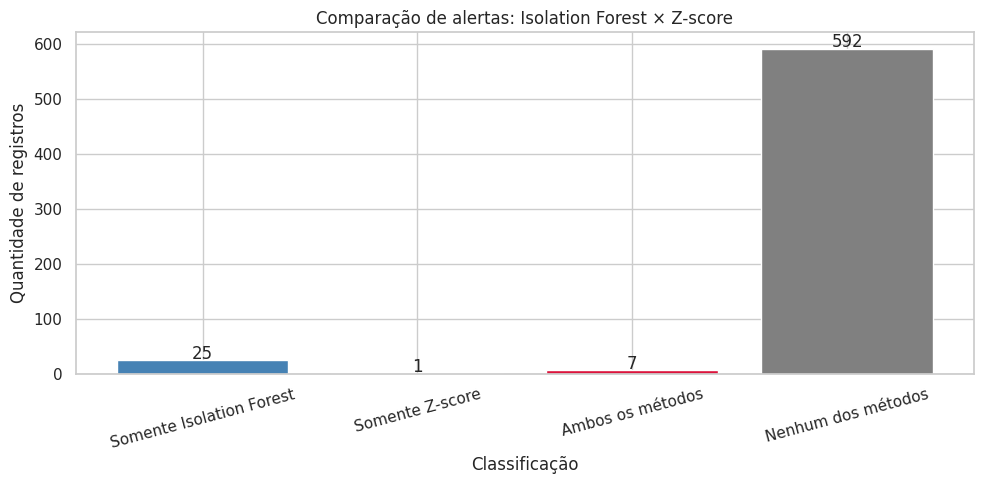

In [ ]:

# Bloco 12 — Comparação entre Isolation Forest e Z-score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Aproveitar os dados padronizados do Bloco 10
# e as classificações do Bloco 11

limite_z = 3.0

# Detectar valores extremos em pelo menos um indicador
alerta_z = (
    X_padronizado.abs() > limite_z
).any(axis=1)

# Construir tabela de comparação
comparacao_metodos = resultados_ml.copy()

comparacao_metodos["Alerta_IF"] = (
    comparacao_metodos["Classificacao"] == -1
)

comparacao_metodos["Alerta_Z"] = alerta_z.to_numpy()

# Identificar a maior distância padronizada por registro
comparacao_metodos["Z_maximo"] = (
    X_padronizado.abs().max(axis=1).to_numpy()
)

# Contagens
somente_if = (
    comparacao_metodos["Alerta_IF"] &
    ~comparacao_metodos["Alerta_Z"]
).sum()

somente_z = (
    ~comparacao_metodos["Alerta_IF"] &
    comparacao_metodos["Alerta_Z"]
).sum()

ambos = (
    comparacao_metodos["Alerta_IF"] &
    comparacao_metodos["Alerta_Z"]
).sum()

nenhum = (
    ~comparacao_metodos["Alerta_IF"] &
    ~comparacao_metodos["Alerta_Z"]
).sum()

resumo = pd.DataFrame({
    "Classificação": [
        "Somente Isolation Forest",
        "Somente Z-score",
        "Ambos os métodos",
        "Nenhum dos métodos"
    ],
    "Quantidade": [
        somente_if,
        somente_z,
        ambos,
        nenhum
    ]
})

print("COMPARAÇÃO DOS MÉTODOS")
display(resumo)

print("\nTOTAL DE ALERTAS POR MÉTODO")
print(
    "Isolation Forest:",
    comparacao_metodos["Alerta_IF"].sum()
)
print(
    "Z-score:",
    comparacao_metodos["Alerta_Z"].sum()
)

# Tabela cruzada
print("\nTABELA CRUZADA")
display(
    pd.crosstab(
        comparacao_metodos["Alerta_IF"],
        comparacao_metodos["Alerta_Z"],
        rownames=["Isolation Forest"],
        colnames=["Z-score"]
    )
)

# Inspecionar alertas exclusivos do Isolation Forest
exclusivos_if = comparacao_metodos[
    comparacao_metodos["Alerta_IF"] &
    ~comparacao_metodos["Alerta_Z"]
].sort_values(
    "Pontuacao_anomalia",
    ascending=False
)

print("\n10 PRINCIPAIS ALERTAS EXCLUSIVOS DO ISOLATION FOREST")

display(
    exclusivos_if[
        ["Data hora"] +
        indicadores +
        ["Pontuacao_anomalia", "Z_maximo"]
    ].head(10).round(3)
)

# Visualização comparativa
fig, ax = plt.subplots(figsize=(10, 5))

cores = [
    "steelblue",
    "darkorange",
    "crimson",
    "gray"
]

ax.bar(
    resumo["Classificação"],
    resumo["Quantidade"],
    color=cores
)

ax.set_title(
    "Comparação de alertas: Isolation Forest × Z-score"
)

ax.set_ylabel("Quantidade de registros")
ax.set_xlabel("Classificação")

for i, valor in enumerate(resumo["Quantidade"]):
    ax.text(
        i,
        valor + 2,
        str(valor),
        ha="center"
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [ ]:

# Bloco 13 — Sensibilidade do Isolation Forest

import pandas as pd
from sklearn.ensemble import IsolationForest

configuracoes = [0.02, 0.05, 0.10]

resultados_sensibilidade = dados_ml[
    ["Data hora"] + indicadores
].copy()

resumo_sensibilidade = []

for contaminacao in configuracoes:

    modelo_teste = IsolationForest(
        n_estimators=200,
        contamination=contaminacao,
        random_state=42,
        n_jobs=-1
    )

    predicoes_teste = modelo_teste.fit_predict(
        X_padronizado
    )

    coluna = f"Alerta_{int(contaminacao * 100)}pct"

    resultados_sensibilidade[coluna] = (
        predicoes_teste == -1
    )

    quantidade = resultados_sensibilidade[coluna].sum()

    resumo_sensibilidade.append({
        "Contaminação configurada": f"{contaminacao:.0%}",
        "Alertas": quantidade,
        "Percentual observado": (
            quantidade / len(resultados_sensibilidade) * 100
        )
    })

print("RESUMO DA ANÁLISE DE SENSIBILIDADE")
display(
    pd.DataFrame(resumo_sensibilidade).round(2)
)

# Comparar os alertas das três configurações
colunas_alerta = [
    "Alerta_2pct",
    "Alerta_5pct",
    "Alerta_10pct"
]

resultados_sensibilidade["Quantidade_configuracoes"] = (
    resultados_sensibilidade[colunas_alerta].sum(axis=1)
)

print("\nCONCORDÂNCIA ENTRE CONFIGURAÇÕES")
display(
    resultados_sensibilidade[
        "Quantidade_configuracoes"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("Número de configurações")
    .reset_index(name="Registros")
)

print("\nREGISTROS SINALIZADOS NAS TRÊS CONFIGURAÇÕES")

alertas_estaveis = resultados_sensibilidade[
    resultados_sensibilidade["Quantidade_configuracoes"] == 3
]

display(
    alertas_estaveis[
        ["Data hora"] +
        indicadores +
        colunas_alerta
    ].round(3)
)

# Verificar se os conjuntos de alertas são aninhados
print("\nVERIFICAÇÃO DE ESTABILIDADE")

alertas_2 = set(
    resultados_sensibilidade.index[
        resultados_sensibilidade["Alerta_2pct"]
    ]
)

alertas_5 = set(
    resultados_sensibilidade.index[
        resultados_sensibilidade["Alerta_5pct"]
    ]
)

alertas_10 = set(
    resultados_sensibilidade.index[
        resultados_sensibilidade["Alerta_10pct"]
    ]
)

print(
    "Todos os alertas de 2% aparecem em 5%?",
    alertas_2.issubset(alertas_5)
)

print(
    "Todos os alertas de 5% aparecem em 10%?",
    alertas_5.issubset(alertas_10)
)


RESUMO DA ANÁLISE DE SENSIBILIDADE


,Contaminação configurada,Alertas,Percentual observado
0,2%,13,2.08
1,5%,32,5.12
2,10%,63,10.08



CONCORDÂNCIA ENTRE CONFIGURAÇÕES


,Número de configurações,Registros
0,0,562
1,1,31
2,2,19
3,3,13



REGISTROS SINALIZADOS NAS TRÊS CONFIGURAÇÕES


,Data hora,pH,Oxigênio Dissolvido (mg/L),Condutividade Elétrica (µS/cm),Turbidez (NTU),Temperatura (°C),Alerta_2pct,Alerta_5pct,Alerta_10pct
408,2026-09-21 09:00:00,6.77,2.19,150.07,2.42,18.94,True,True,True
409,2026-09-21 10:00:00,6.51,1.97,149.63,2.49,18.94,True,True,True
410,2026-09-21 11:00:00,6.40,1.64,148.01,2.78,18.91,True,True,True
411,2026-09-21 12:00:00,6.36,1.25,145.87,3.00,18.82,True,True,True
412,2026-09-21 13:00:00,6.35,1.01,145.53,3.10,18.78,True,True,True
413,2026-09-21 14:00:00,6.36,0.94,145.22,3.07,18.78,True,True,True
414,2026-09-21 15:00:00,6.39,0.93,146.08,3.04,18.79,True,True,True
555,2026-09-27 12:00:00,8.87,10.38,139.07,1.68,23.70,True,True,True
556,2026-09-27 13:00:00,9.03,10.67,139.18,2.04,23.75,True,True,True
557,2026-09-27 14:00:00,9.07,10.77,139.25,2.35,23.74,True,True,True



VERIFICAÇÃO DE ESTABILIDADE
Todos os alertas de 2% aparecem em 5%? True
Todos os alertas de 5% aparecem em 10%? True
